# 05 — Resultados e Análises de Sensibilidade

Este notebook reúne a leitura substantiva dos resultados finais: o contraste principal de 2014 a 2024, a comparação com a formulação C, a estabilidade entre especificações de modelo, o recorte de suporte, a inferência municipal e as limitações.

Todos os valores são lidos dos artefatos da execução científica original (`outputs/temporal/estimacao_v2/`). Nenhum modelo é ajustado aqui.

**Convenção:** contraste = risco padronizado de baixo peso com início no 1º–3º mês **menos** o risco com início tardio, em pontos percentuais (p.p.). **Valores negativos indicam menor risco no início precoce.**

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ------------------------------------------------------------
# Raiz do projeto: procurada nos diretórios pais, sem caminho fixo
# ------------------------------------------------------------
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "temporal.py").exists()
     and (p / "docs" / "entrega" / "METADADOS_BASE.md").exists()),
    None,
)
if raiz is None:
    raise FileNotFoundError(f"Raiz do projeto não encontrada a partir de {cwd}")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

venv_projeto = (raiz / ".venv").resolve()
if Path(sys.prefix).resolve() != venv_projeto:
    print(f"Atenção: o kernel não está usando a .venv do projeto ({venv_projeto}).")

from src.visualizacao import CORES_IPT, aplicar_tema_base, configurar_plotly

configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ANOS = list(range(2014, 2025))
ESTIMACAO = raiz / "outputs" / "temporal" / "estimacao_v2"
TABELAS = raiz / "outputs" / "temporal" / "tabelas"
AUDITORIA_V1 = raiz / "outputs" / "temporal" / "estimativas"


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def mostrar(fig, titulo, altura=460, largura=950, margem_esquerda=None):
    """Aplica a identidade visual IPT e exibe a figura."""
    aplicar_tema_base(fig, titulo)
    fig.update_layout(width=largura, height=altura, separators=",.")
    if margem_esquerda is not None:
        fig.update_layout(margin_l=margem_esquerda)
    fig.show()


def formatar(tabela, casas=2):
    """Converte uma tabela numérica para texto no padrão brasileiro."""
    return tabela.map(lambda v: "—" if pd.isna(v) else num(v, casas))


def pp(valor, casas=3):
    """Valor em pontos percentuais com sinal de menos tipográfico."""
    return num(valor, casas).replace("-", "−")


print("Raiz do projeto localizada:", raiz.name)

Raiz do projeto localizada: big-data-sinasc-causal-ml


In [2]:
resultados = pd.read_csv(ESTIMACAO / "resultados_anuais.csv")
recorte = pd.read_csv(ESTIMACAO / "trimming.csv")
influencia = pd.read_csv(ESTIMACAO / "influencia.csv")
manifesto = json.loads((ESTIMACAO / "manifesto_estimacao_v2.json").read_text(encoding="utf-8"))

sem_recorte = (resultados.query("trimming == 'sem_trimming' and formulacao in ['B', 'C']")
               .set_index(["formulacao", "especificacao", "ano"]).sort_index())
assert len(sem_recorte) == 2 * 3 * len(ANOS)


def serie(formulacao, especificacao="C1"):
    """Resultados anuais de uma formulação e especificação, sem recorte."""
    return sem_recorte.loc[(formulacao, especificacao)]


# Conferência com os valores publicados em docs/entrega_1_nacional_aipw/TABELAS_RESULTADOS.md (Tabela 2)
B1 = serie("B")
assert list(B1.index) == ANOS
assert list(B1.estimativa_pp.round(3)) == [-0.936, -1.003, -1.090, -1.126, -1.256, -1.210,
                                           -1.066, -1.252, -1.524, -1.429, -1.480]
print("Resultados carregados e conferidos com a Tabela 2 do relatório.")

Resultados carregados e conferidos com a Tabela 2 do relatório.


## 1. Resultado principal: formulação B, especificação C1

T = 1: início no 1º–3º mês; T = 0: início no 4º–6º mês. Estimativas sem recorte de suporte, com IC95% municipal.

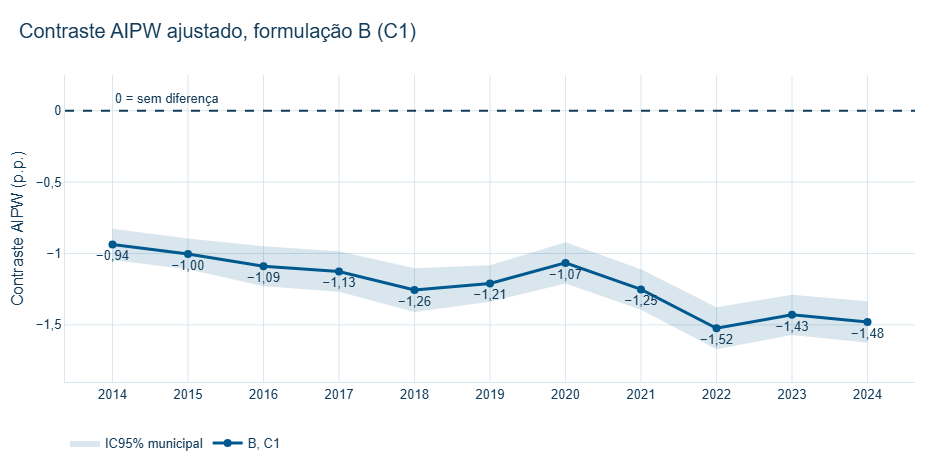

,N,C1 (p.p.),IC95% municipal,Suporte
Ano,,,,
2014,2.615.773,"−0,936","−1,046 a −0,827",Aprovado
2015,2.673.272,"−1,003","−1,111 a −0,896",Aprovado
2016,2.560.827,"−1,090","−1,230 a −0,949",Aprovado
2017,2.630.828,"−1,126","−1,268 a −0,984",Aprovado
2018,2.672.423,"−1,256","−1,409 a −1,103",Aprovado
2019,2.586.743,"−1,210","−1,339 a −1,082",Aprovado
2020,2.476.058,"−1,066","−1,210 a −0,922",Aprovado
2021,2.425.844,"−1,252","−1,394 a −1,110",Aprovado
2022,2.344.255,"−1,524","−1,671 a −1,377",Aprovado


Maior limite superior do IC95% municipal: −0,827 p.p. (2014).


In [3]:
AZUL_FAIXA = "rgba(0, 89, 142, 0.15)"
fig = go.Figure()
fig.add_scatter(x=ANOS + ANOS[::-1],
                y=list(B1.ic95_cluster_superior_pp) + list(B1.ic95_cluster_inferior_pp[::-1]),
                fill="toself", fillcolor=AZUL_FAIXA, line_width=0, name="IC95% municipal", hoverinfo="skip")
fig.add_scatter(x=ANOS, y=B1.estimativa_pp, mode="lines+markers+text", name="B, C1",
                text=[pp(v, 2) for v in B1.estimativa_pp], textposition="bottom center",
                line=dict(color=CORES_IPT["AZUL_PRINCIPAL"], width=3), marker=dict(size=8))
fig.add_hline(y=0, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"], line_width=2)
fig.add_annotation(x=2014, y=0, text="0 = sem diferença", showarrow=False, yshift=12, xanchor="left")
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="Contraste AIPW (p.p.)", range=[-1.9, 0.25])
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Contraste AIPW ajustado, formulação B (C1)", altura=470)

situacao = {"APROVADO": "Aprovado", "SINALIZADO": "Sinalizado"}
display(pd.DataFrame({
    "N": B1.n.map(num),
    "C1 (p.p.)": B1.estimativa_pp.map(pp),
    "IC95% municipal": [f"{pp(i)} a {pp(s)}" for i, s in zip(B1.ic95_cluster_inferior_pp, B1.ic95_cluster_superior_pp)],
    "Suporte": B1.status_suporte_09d.map(situacao),
}).rename_axis("Ano"))

assert (B1.estimativa_pp < 0).all() and (B1.ic95_cluster_superior_pp < 0).all()
print(f"Maior limite superior do IC95% municipal: {pp(B1.ic95_cluster_superior_pp.max())} p.p. "
      f"({B1.ic95_cluster_superior_pp.idxmax()}).")

- **O contraste é negativo nos 11 anos.** O risco padronizado de baixo peso é menor com início no 1º–3º mês do que com início no 4º–6º mês.
- A magnitude vai de **−0,936 p.p. (2014)** a **−1,524 p.p. (2022)**, diante de uma prevalência de baixo peso de 7% a 8%.
- **Nenhum intervalo de confiança inclui zero.** O maior limite superior é −0,827 p.p., em 2014.
- 2024 está sinalizado por caudas de propensão (notebook 03), e não por falta de suporte. A seção 4 mostra que o recorte dessas caudas quase não muda a estimativa.

## 2. Formulação B versus formulação C

A formulação C usa um comparador mais restrito: início no **4º–5º mês**, excluindo o 6º. Ela afasta ainda mais o comparador da região afetada pelo problema temporal descrito no notebook 02.

> **B e C têm populações e estimandos diferentes.** C não "corrige" B: ela verifica se a conclusão depende de incluir o 6º mês no comparador. Diferenças entre B e C refletem perguntas diferentes, e não o erro de uma delas.

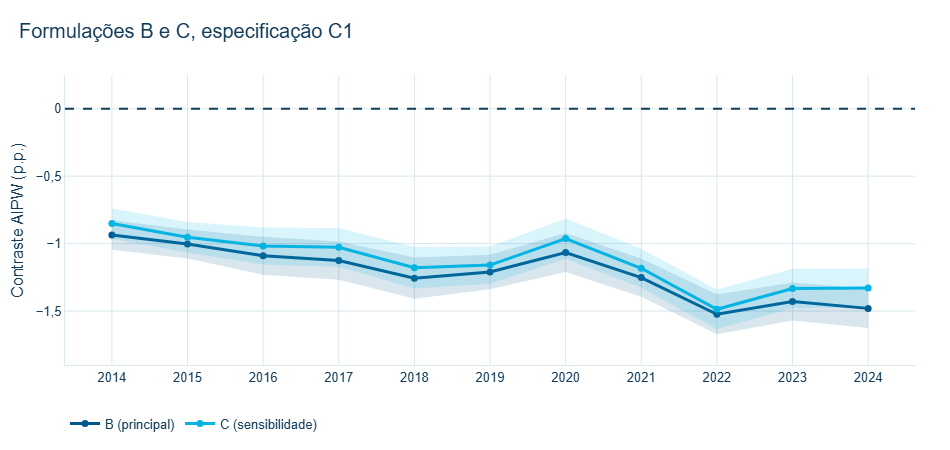

C − B: de +0,037 p.p. (2022) a +0,150 p.p. (2024). Maior limite superior do IC de C: −0,740 p.p.


In [4]:
C1c = serie("C")
fig = go.Figure()
for nome, s, cor, faixa in (("B (principal)", B1, CORES_IPT["AZUL_PRINCIPAL"], AZUL_FAIXA),
                            ("C (sensibilidade)", C1c, CORES_IPT["CIANO"], "rgba(4, 180, 227, 0.15)")):
    fig.add_scatter(x=ANOS + ANOS[::-1],
                    y=list(s.ic95_cluster_superior_pp) + list(s.ic95_cluster_inferior_pp[::-1]),
                    fill="toself", fillcolor=faixa, line_width=0, showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=ANOS, y=s.estimativa_pp, mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3), marker=dict(size=7))
fig.add_hline(y=0, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"], line_width=2)
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="Contraste AIPW (p.p.)", range=[-1.9, 0.25])
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Formulações B e C, especificação C1", altura=450)

diferenca = C1c.estimativa_pp - B1.estimativa_pp
assert (diferenca > 0).all() and (C1c.estimativa_pp < 0).all() and (C1c.ic95_cluster_superior_pp < 0).all()
print(f"C − B: de +{num(diferenca.min(), 3)} p.p. ({diferenca.idxmin()}) a +{num(diferenca.max(), 3)} p.p. "
      f"({diferenca.idxmax()}). Maior limite superior do IC de C: {pp(C1c.ic95_cluster_superior_pp.max())} p.p.")

- **O padrão temporal é o mesmo** nas duas formulações.
- **C é ligeiramente menos negativo que B em todos os anos**, com diferença entre 0,04 e 0,15 p.p.
- Todos os intervalos de C também ficam abaixo de zero.

## 3. Especificações C1, C2 e C3

As três especificações trocam os modelos auxiliares (notebook 04): C1 é toda logística; C2 usa desfechos HGB; C3 usa propensão e desfechos HGB.

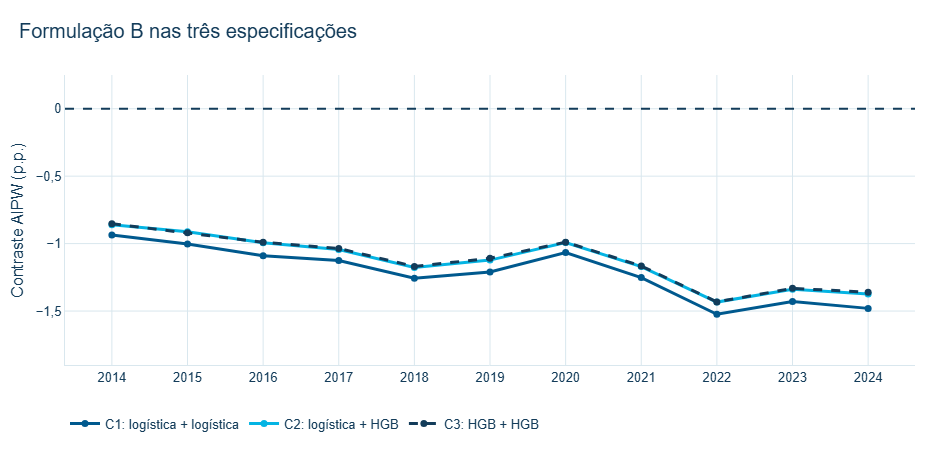

,Maior |C2 − C3| (p.p.),C1 abaixo de C2 e C3 (p.p.),Todas negativas
Formulação,,,
B,"0,013","0,07 a 0,12",sim
C,"0,012","0,07 a 0,12",sim


In [5]:
fig = go.Figure()
estilos = (("C1", "C1: logística + logística", CORES_IPT["AZUL_PRINCIPAL"], "solid"),
           ("C2", "C2: logística + HGB", CORES_IPT["CIANO"], "solid"),
           ("C3", "C3: HGB + HGB", CORES_IPT["AZUL_ESCURO"], "dash"))
for especificacao, nome, cor, traco in estilos:
    fig.add_scatter(x=ANOS, y=serie("B", especificacao).estimativa_pp, mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3, dash=traco), marker=dict(size=7))
fig.add_hline(y=0, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"], line_width=2)
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="Contraste AIPW (p.p.)", range=[-1.9, 0.25])
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Formulação B nas três especificações", altura=450)

linhas = {}
for f in ("B", "C"):
    c1_, c2_, c3_ = (serie(f, e).estimativa_pp for e in ("C1", "C2", "C3"))
    flexiveis = pd.concat([c2_ - c1_, c3_ - c1_])
    linhas[f] = {"Maior |C2 − C3| (p.p.)": num((c2_ - c3_).abs().max(), 3),
                 "C1 abaixo de C2 e C3 (p.p.)": f"{num(flexiveis.min(), 2)} a {num(flexiveis.max(), 2)}",
                 "Todas negativas": "sim" if sem_recorte.loc[f].estimativa_pp.lt(0).all() else "não"}
display(pd.DataFrame(linhas).T.rename_axis("Formulação"))

- **C2 ≈ C3.** A maior diferença anual entre elas é de cerca de 0,01 p.p. Trocar a propensão logística pela HGB quase não muda o resultado.
- **C1 é um pouco mais negativo**, entre 0,07 e 0,12 p.p. abaixo de C2 e C3. A diferença vem dos modelos de desfecho (logístico versus HGB).
- **Não há mudança de sinal nem de ordem de grandeza.** A forma da série temporal é a mesma nas três especificações.

## 4. Recorte de suporte (*trimming*)

O recorte mantém apenas os registros com e(X) em **[0,05; 0,95]** e recalcula o AIPW com as mesmas previsões do ajuste cruzado. Ele testa se as caudas sinalizadas no notebook 03 movem o resultado. Como o recorte também muda a população, ele é apenas uma **sensibilidade**: a estimativa principal é sempre a sem recorte.

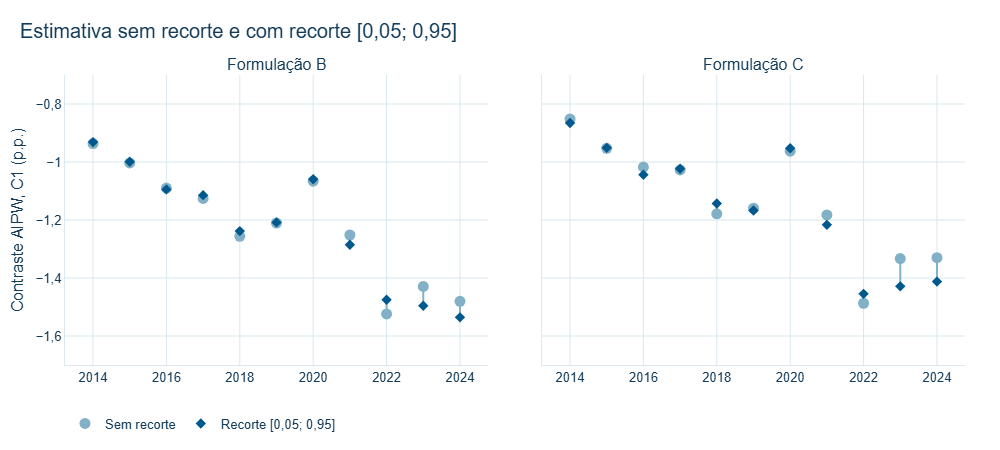

,Registros excluídos (%),Maior mudança em C1 (p.p.),"Registros fora de [0,01; 0,99]",Algum IC passa a incluir zero?
Formulação,,,,
B,"6,22 a 10,56","0,067 (2023)",0,não
C,"8,14 a 14,94","0,096 (2023)",0,não


In [6]:
r1 = recorte[recorte.especificacao == "C1"].set_index(["formulacao", "ano"]).sort_index()

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.06,
                    subplot_titles=["Formulação B", "Formulação C"])
for coluna, f in enumerate(("B", "C"), start=1):
    s = r1.loc[f]
    xs, ys = [], []
    for ano, linha in s.iterrows():
        xs += [ano, ano, None]
        ys += [linha.estimativa_pp_sem_trimming, linha.estimativa_pp_005_095, None]
    fig.add_scatter(x=xs, y=ys, mode="lines", line=dict(color=CORES_IPT["AZUL_CLARO"], width=2),
                    showlegend=False, hoverinfo="skip", row=1, col=coluna)
    fig.add_scatter(x=s.index, y=s.estimativa_pp_sem_trimming, mode="markers", name="Sem recorte",
                    marker=dict(color=CORES_IPT["AZUL_CLARO"], size=11), showlegend=coluna == 1, row=1, col=coluna)
    fig.add_scatter(x=s.index, y=s.estimativa_pp_005_095, mode="markers", name="Recorte [0,05; 0,95]",
                    marker=dict(color=CORES_IPT["AZUL_PRINCIPAL"], size=8, symbol="diamond"),
                    showlegend=coluna == 1, row=1, col=coluna)
fig.update_xaxes(dtick=2)
fig.update_yaxes(title="Contraste AIPW, C1 (p.p.)", range=[-1.7, -0.7], row=1, col=1)
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Estimativa sem recorte e com recorte [0,05; 0,95]", altura=450, largura=1000)

todas = recorte.query("formulacao in ['B', 'C']")
resumo = {}
for f in ("B", "C"):
    s = r1.loc[f]
    maior = s.delta_trimming_pp.abs()
    resumo[f] = {
        "Registros excluídos (%)": f"{num(s.pct_excluido.min(), 2)} a {num(s.pct_excluido.max(), 2)}",
        "Maior mudança em C1 (p.p.)": f"{num(maior.max(), 3)} ({maior.idxmax()})",
        "Registros fora de [0,01; 0,99]": int(todas[todas.formulacao == f].fora_001_099_n.sum()),
        "Algum IC passa a incluir zero?": "sim" if (todas[todas.formulacao == f].ic95_cluster_superior_pp_005_095 >= 0).any() else "não",
    }
tabela_recorte = pd.DataFrame(resumo).T.rename_axis("Formulação")
assert tabela_recorte.loc["B", "Maior mudança em C1 (p.p.)"] == "0,067 (2023)"
assert tabela_recorte.loc["C", "Maior mudança em C1 (p.p.)"] == "0,096 (2023)"
assert tabela_recorte.loc["B", "Registros excluídos (%)"] == "6,22 a 10,56"
assert tabela_recorte.loc["C", "Registros excluídos (%)"] == "8,14 a 14,94"
display(tabela_recorte)

- O recorte exclui de **6,22% a 10,56%** dos registros em B e de **8,14% a 14,94%** em C.
- A estimativa quase não se move: a maior mudança é de **0,067 p.p. em B** e **0,096 p.p. em C**, ambas em 2023. Nos dois casos, a mudança é inferior a 0,1 p.p., contra contrastes da ordem de 1 p.p.
- **Nenhum registro fica fora de [0,01; 0,99]**, e nenhum intervalo passa a incluir zero após o recorte, em nenhuma especificação.

As caudas sinalizadas no notebook 03 não sustentam o resultado: removê-las não muda a leitura.

## 5. Evolução temporal

Os anos são estimados separadamente, e o gráfico da seção 1 permite descrever a forma da série em B (C1):

In [7]:
v = B1.estimativa_pp
assert v.idxmin() == 2022
assert v[2014] > v[2018] and v[2020] > v[2019] and v[2020] > v[2021]
for ano in (2014, 2018, 2019, 2020, 2021, 2022, 2023, 2024):
    print(f"{ano}: {pp(v[ano])} p.p.")

2014: −0,936 p.p.
2018: −1,256 p.p.
2019: −1,210 p.p.
2020: −1,066 p.p.
2021: −1,252 p.p.
2022: −1,524 p.p.
2023: −1,429 p.p.
2024: −1,480 p.p.


- **2014 → 2018/2019:** a magnitude do contraste aumenta;
- **2020:** há um recuo;
- **2021:** a magnitude volta a crescer;
- **2022:** ocorre a maior magnitude da série;
- **2023–2024:** a magnitude permanece elevada.

**O que essa descrição não autoriza:**

- não foi feito teste formal de quebra estrutural nem de diferença entre anos;
- os intervalos anuais não levam em conta a dependência entre anos;
- o recuo de 2020 **não** é atribuído à pandemia de COVID-19;
- o pico de 2022 **não** é atribuído a nenhuma política ou evento.

No mesmo período também mudam a prevalência de baixo peso, a proporção de início precoce e a composição da população (notebook 01). A série é um retrato descritivo de contrastes anuais, e não uma série de efeitos de intervenções.

## 6. Inferência municipal

O erro-padrão principal é agrupado por município de residência (notebook 04). A comparação com o erro-padrão iid mostra quanto a dependência dentro dos municípios aumenta a incerteza.

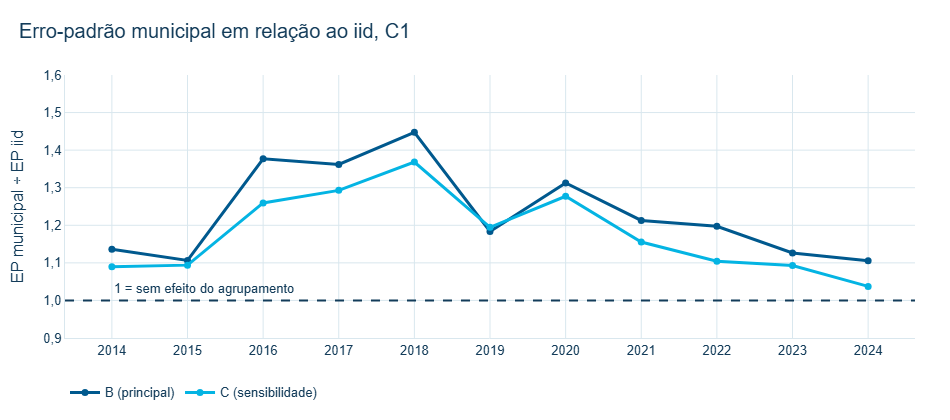

B, todas as especificações: EP municipal entre 1,10 e 1,47 vez o EP iid.
C, todas as especificações: EP municipal entre 1,04 e 1,38 vez o EP iid.


In [8]:
fig = go.Figure()
for nome, s, cor in (("B (principal)", B1, CORES_IPT["AZUL_PRINCIPAL"]), ("C (sensibilidade)", C1c, CORES_IPT["CIANO"])):
    fig.add_scatter(x=ANOS, y=s.razao_se_cluster_iid, mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3), marker=dict(size=7))
fig.add_hline(y=1, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"], line_width=2)
fig.add_annotation(x=2014, y=1, text="1 = sem efeito do agrupamento", showarrow=False, yshift=12, xanchor="left")
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="EP municipal ÷ EP iid", range=[0.9, 1.6], tickformat=".1f")
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Erro-padrão municipal em relação ao iid, C1", altura=420)

assert (sem_recorte.razao_se_cluster_iid > 1).all()
for f in ("B", "C"):
    r = sem_recorte.loc[f].razao_se_cluster_iid
    print(f"{f}, todas as especificações: EP municipal entre {num(r.min(), 2)} e {num(r.max(), 2)} vez o EP iid.")

- **O erro-padrão municipal é sempre maior que o iid:** de 1,10 a 1,47 vez em B e de 1,04 a 1,38 vez em C.
- Observações do mesmo município não são tratadas como totalmente independentes: elas compartilham serviços de saúde e contexto. Ignorar isso produziria intervalos estreitos demais.
- Mesmo com a correção, todos os intervalos permanecem abaixo de zero (seções 1 e 2).

## 7. Municípios influentes

Em alguns anos, poucos municípios grandes concentram uma parte relevante da variabilidade das contribuições ψᵢ. Isso foi examinado em análises históricas, sem novos ajustes, e não é reaberto aqui. O resumo abaixo apenas lê os artefatos existentes.

In [9]:
conc = influencia.query("formulacao == 'B' and especificacao == 'C1'").set_index("ano").max_fracao_u2_municipio
loco = pd.read_csv(AUDITORIA_V1 / "auditoria_loco_municipios.csv")
estresse = pd.read_csv(AUDITORIA_V1 / "auditoria_stress_clusters.csv")
assert sorted(conc.index[conc > 0.15]) == [2016, 2017, 2018, 2020, 2021]
assert not loco.sinal_mudou.any() and not loco.ic_passa_a_incluir_zero.any()
assert not estresse.sinal_mudou.any() and not estresse.ic_passa_a_incluir_zero.any()

print(f"B (C1): o município de maior contribuição responde por {num(100 * conc.min(), 1)}% ({conc.idxmin()}) a "
      f"{num(100 * conc.max(), 1)}% ({conc.idxmax()}) da variância municipal do ano.")
print(f"Análises históricas (formulação A): {len(loco)} remoções de um município por vez e {len(estresse)} "
      f"remoções conjuntas dos 5 ou 10 mais influentes.")
print(f"  Maior mudança: {num(loco.delta_pp.abs().max(), 3)} p.p. (um município) e "
      f"{num(estresse.delta_pp.abs().max(), 3)} p.p. (5 ou 10 municípios). "
      f"Mudanças de sinal: 0. ICs municipais que passam a incluir zero: 0.")

B (C1): o município de maior contribuição responde por 4,6% (2024) a 21,9% (2020) da variância municipal do ano.
Análises históricas (formulação A): 150 remoções de um município por vez e 30 remoções conjuntas dos 5 ou 10 mais influentes.
  Maior mudança: 0,039 p.p. (um município) e 0,121 p.p. (5 ou 10 municípios). Mudanças de sinal: 0. ICs municipais que passam a incluir zero: 0.


- **Diagnóstico de influência da V2 (B, C1):** houve concentração de influência municipal em alguns anos. O município de maior contribuição responde por 17% a 22% da variância municipal em 2016–2018 e 2020–2021, contra 4,6% a 10,6% nos demais anos.
- **Remoções históricas (formulação A, V1):** as remoções de um município por vez e dos 5 ou 10 mais influentes não encontraram mudança de sinal nem intervalo municipal incluindo zero.

Essas remoções não foram executadas em B ou C. Elas indicam que o resultado histórico não depende de um município específico, mas não substituem uma auditoria equivalente de B e C.

## 8. Limitações

| Limitação | O que significa | Consequência para a leitura |
| --- | --- | --- |
| **Confundimento residual** | renda, tabagismo, estado nutricional, morbidades prévias e gravidez planejada não estão (ou não estão completamente) em X | a magnitude pode estar inflada: gestantes mais saudáveis e com mais recursos tendem a iniciar cedo; a dupla robustez não corrige isso |
| **Seleção por nascido vivo** | o SINASC registra apenas gestações que terminaram em nascimento vivo | o resultado vale para nascidos vivos elegíveis, e não para todas as gestações |
| **`MESPRENAT` retrospectivo** | o mês de início é preenchido no parto, sem validação direta conhecida; mês desconhecido é excluído | possível erro de classificação de T |
| **Problema temporal residual** | B reduz, mas não elimina, a ligação entre duração da gestação e classificação do início | parte do contraste ainda pode refletir a duração da gestação |
| **Dependência entre anos não modelada** | os intervalos são anuais e não incorporam correlação entre anos | diferenças entre anos não são testes formais |
| **Caudas de propensão sinalizadas** | B/2024 e C/2017–2024 têm mais de 10% dos registros com e(X) fora de [0,05; 0,95] | anos mantidos e reportados com ressalva; o recorte mostra baixa sensibilidade |

Fonte: [relatório final](../../docs/entrega_1_nacional_aipw/RELATORIO_FINAL_DISCIPLINA.md), seção 23, e manifesto da estimação.

## 9. Conclusão

Na população principal B, entre 2014 e 2024, **o início do pré-natal no 1º trimestre está associado a um risco de baixo peso ao nascer aproximadamente 0,9 a 1,5 ponto percentual menor** do que o início no 4º–6º mês, após ajuste por sete características maternas e geográficas.

Esse padrão:

- aparece nos **11 anos**, sempre com intervalo municipal abaixo de zero;
- é **estável entre as três especificações** de modelo (C1, C2 e C3);
- **reaparece na formulação C**, com comparador mais restrito;
- é **pouco sensível ao recorte** de suporte (mudanças inferiores a 0,1 p.p.).

**Mas:** trata-se de uma estimativa **sob hipóteses de identificação**, e não de causalidade comprovada. O estudo é observacional, há confundimento residual plausível, a população é condicionada ao nascimento vivo e o mês de início é registrado retrospectivamente. O resultado é compatível com a recomendação de iniciar o pré-natal no primeiro trimestre, mas não quantifica o ganho de uma intervenção específica.

## 10. O que o projeto demonstrou como Big Data

In [10]:
descritiva = pd.read_csv(TABELAS / "descritiva_anual.csv").set_index("ano")
execucao = pd.read_csv(ESTIMACAO / "execucao.csv")
assert descritiva.n_bruto.sum() == 30_468_409 and B1.n.sum() == 27_533_362

display(pd.DataFrame({"Valor": [
    f"{num(descritiva.n_bruto.sum())} registros brutos, {len(ANOS)} anos",
    f"{num(B1.n.sum())} nascidos vivos",
    f"{num(B1.n_clusters.min())} a {num(B1.n_clusters.max())} por ano",
    f"{num((execucao.ajustes_novos + execucao.ajustes_reutilizados).sum())}",
    f"{num(execucao.segundos_fit_checkpoints.sum() / 3600, 1)} horas",
    f"{num(manifesto['rss_pico_bytes'] / 1e9, 1)} GB",
]}, index=pd.Index(["Volume processado", "População principal (B)", "Municípios (clusters de inferência)",
                    "Ajustes de modelos auxiliares", "Tempo total de ajuste", "Pico de memória da estimação"],
                   name="Escala do projeto")))

,Valor
Escala do projeto,
Volume processado,"30.468.409 registros brutos, 11 anos"
População principal (B),27.533.362 nascidos vivos
Municípios (clusters de inferência),5.580 a 5.587 por ano
Ajustes de modelos auxiliares,414
Tempo total de ajuste,"2,0 horas"
Pico de memória da estimação,"2,6 GB"


- **Volume:** 30,5 milhões de registros do SINASC, em 11 anos, analisados integralmente, sem amostragem.
- **Armazenamento e consulta:** os arquivos oficiais foram convertidos para **Parquet** e consultados com **DuckDB**, o que permitiu filtrar e agregar milhões de linhas diretamente nos arquivos, sem carregar a base inteira na memória.
- **Processamento anual:** cada ano é carregado e estimado separadamente. Isso mantém o uso de memória limitado (pico em torno de 2,6 GB) e torna cada etapa reexecutável de forma independente.
- **Machine learning a serviço da inferência:** os modelos de ML (regressão logística e gradient boosting) não são o produto final. Eles estimam as funções auxiliares e(X), m₀(X) e m₁(X), com ajuste cruzado para reduzir o risco de viés por sobreajuste.
- **Inferência causal explícita:** estimando definido antes dos resultados, hipóteses declaradas, diagnósticos de suporte e sensibilidades pré-especificadas.
- **Visualização e reprodutibilidade:** os notebooks de entrega leem os artefatos da execução científica, sem reajustar modelos, e conferem automaticamente os números exibidos contra as tabelas publicadas.

Grande volume aumenta a precisão, mas **não remove o viés de confundimento**. O valor do projeto está em combinar escala com um desenho causal transparente sobre os próprios limites.